#  **🛑 (Data Understanding & Visualization)**


# Import libraries


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split

print("Libraries imported successfully")

Libraries imported successfully


# Load dataset and Show first 5 rows


In [2]:
df = pd.read_csv('/kaggle/input/datasets/altruistdelhite04/loan-prediction-problem-dataset/train_u6lujuX_CVtuZ9i.csv')

df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


# Dataset Shape


In [3]:
# Shows number of rows and columns.

print("Rows and Columns:", df.shape)

Rows and Columns: (614, 13)


# Features

In [4]:
# Displays all dataset features.

print(df.columns)

Index(['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education',
       'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status'],
      dtype='object')


# Data Information

In [5]:
# Shows data types and missing values.

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


# Statistical Summary

In [6]:
# Displays mean, min, max, and other statistics.

df.describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.000000,614.000000,592.000000,600.00000,564.000000
mean,5403.459283,1621.245798,146.412162,342.00000,0.842199
std,6109.041673,2926.248369,85.587325,65.12041,0.364878
min,150.000000,0.000000,9.000000,12.00000,0.000000
25%,2877.500000,0.000000,100.000000,360.00000,1.000000
50%,3812.500000,1188.500000,128.000000,360.00000,1.000000
75%,5795.000000,2297.250000,168.000000,360.00000,1.000000
max,81000.000000,41667.000000,700.000000,480.00000,1.000000


# Missing Values

In [7]:
# Checks missing data in each column.

df.isnull().sum()

Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

# Loan Status Distribution
# Shows approved vs rejected loans.

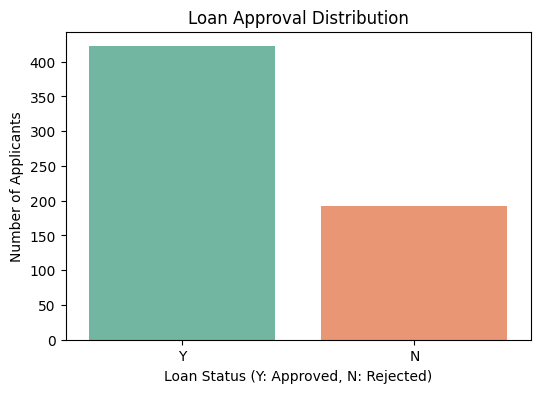

In [8]:

plt.figure(figsize=(6, 4))  
sns.countplot(x='Loan_Status', data=df, palette='Set2') 
plt.title("Loan Approval Distribution")
plt.xlabel("Loan Status (Y: Approved, N: Rejected)") 
plt.ylabel("Number of Applicants") 
plt.show()


# Education vs Loan Status 

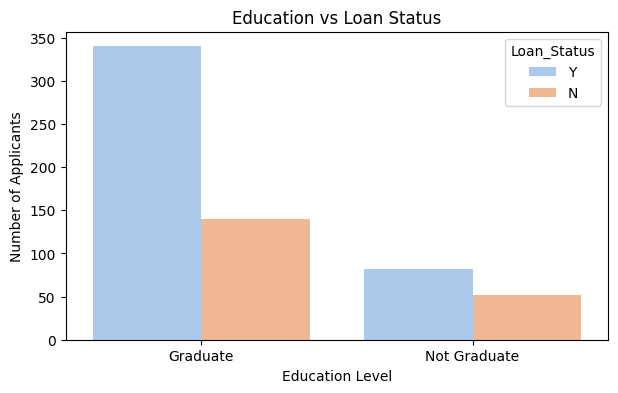

In [9]:

# Education Effect
# Compares education level with loan approval.

plt.figure(figsize=(7, 4))  
sns.countplot(x='Education', hue='Loan_Status', data=df, palette='pastel')
plt.title("Education vs Loan Status")
plt.xlabel("Education Level")    
plt.ylabel("Number of Applicants")    
plt.show()


# Credit History vs Loan Status 

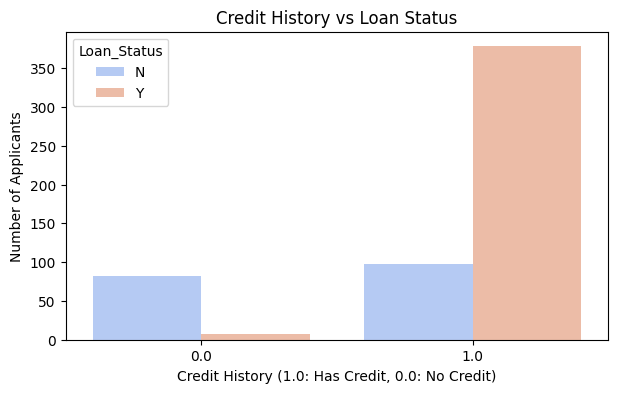

In [10]:
# Credit History Impact
# Shows how credit history affects approval.

plt.figure(figsize=(7, 4))
sns.countplot(x='Credit_History', hue='Loan_Status', data=df, palette='coolwarm')
plt.title("Credit History vs Loan Status")
plt.xlabel("Credit History (1.0: Has Credit, 0.0: No Credit)")
plt.ylabel("Number of Applicants") 
plt.show()

# **🛑 (Data Preprocessing)**

# Check Missing Values

In [11]:

print('=== Missing Values ===')
missing = df.isnull().sum()
missing_pct = (df.isnull().sum() / len(df) * 100).round(2)
missing_df = pd.DataFrame({'Missing Count': missing, 'Percentage %': missing_pct})
print(missing_df[missing_df['Missing Count'] > 0])


=== Missing Values ===
                  Missing Count  Percentage %
Gender                       13          2.12
Married                       3          0.49
Dependents                   15          2.44
Self_Employed                32          5.21
LoanAmount                   22          3.58
Loan_Amount_Term             14          2.28
Credit_History               50          8.14


# Handle Missing Values

In [12]:
# Categorical columns → fill with Mode
categorical_cols = ['Gender', 'Married', 'Dependents', 'Self_Employed']
for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

# Numerical columns → fill with Median
numeric_cols = ['LoanAmount', 'Loan_Amount_Term', 'Credit_History']
for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())

print('After Handling - Missing Values:')
print(df.isnull().sum())


After Handling - Missing Values:
Loan_ID              0
Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0
dtype: int64


#  Label Encoding

In [13]:
le = LabelEncoder()
cols_to_encode = ['Gender', 'Married', 'Dependents', 'Education',
                  'Self_Employed', 'Property_Area', 'Loan_Status']

for col in cols_to_encode:
    df[col] = le.fit_transform(df[col])

print('After Encoding:')
print(df.head())


After Encoding:
    Loan_ID  Gender  Married  Dependents  Education  Self_Employed  \
0  LP001002       1        0           0          0              0   
1  LP001003       1        1           1          0              0   
2  LP001005       1        1           0          0              1   
3  LP001006       1        1           0          1              0   
4  LP001008       1        0           0          0              0   

   ApplicantIncome  CoapplicantIncome  LoanAmount  Loan_Amount_Term  \
0             5849                0.0       128.0             360.0   
1             4583             1508.0       128.0             360.0   
2             3000                0.0        66.0             360.0   
3             2583             2358.0       120.0             360.0   
4             6000                0.0       141.0             360.0   

   Credit_History  Property_Area  Loan_Status  
0             1.0              2            1  
1             1.0              0        

# Define X and y

In [14]:
df = df.drop(columns=['Loan_ID'])

X = df.drop(columns=['Loan_Status'])
y = df['Loan_Status']

print('X shape:', X.shape)
print('y shape:', y.shape)


X shape: (614, 11)
y shape: (614,)


# Train / Test Split

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f'Training set: {X_train.shape}')
print(f'Testing set:  {X_test.shape}')


Training set: (491, 11)
Testing set:  (123, 11)


# Feature Scaling

In [16]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

print('✅ Data is ready for modeling!')
print(f'X_train_scaled shape: {X_train_scaled.shape}')
print(f'X_test_scaled shape:  {X_test_scaled.shape}')


✅ Data is ready for modeling!
X_train_scaled shape: (491, 11)
X_test_scaled shape:  (123, 11)


# 🛑 Model Implementation



In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

print("Libraries imported successfully ✅")


Libraries imported successfully ✅


## Model 1: Logistic Regression


In [18]:
# Build and Train Model 1: Logistic Regression
model1 = LogisticRegression(random_state=42, max_iter=1000)
model1.fit(X_train_scaled, y_train)

# Predictions
y_pred1 = model1.predict(X_test_scaled)
print("Model 1 - Sample predictions:", y_pred1[:10])


Model 1 - Sample predictions: [0 1 1 1 1 1 1 1 1 1]


## Model 2: Random Forest


In [19]:
# Build and Train Model 2: Random Forest
model2 = RandomForestClassifier(n_estimators=100, random_state=42)
model2.fit(X_train_scaled, y_train)

# Predictions
y_pred2 = model2.predict(X_test_scaled)
print("Model 2 - Sample predictions:", y_pred2[:10])


Model 2 - Sample predictions: [0 1 1 1 1 1 1 1 0 1]


# Evaluation



In [20]:
#  import the library
from sklearn.metrics import (accuracy_score, classification_report, 
                              confusion_matrix, ConfusionMatrixDisplay)
import matplotlib.pyplot as plt


**Confusion Matrix — Shows where the model makes mistakes**

**Accuracy — Percentage of correct predictions**

**Classification Report — Precision, Recall, and F1 for each class**


# The first model

Model 1 - Accuracy: 0.8618

Model 1 - Classification Report:
              precision    recall  f1-score   support

    Rejected       0.96      0.58      0.72        38
    Approved       0.84      0.99      0.91        85

    accuracy                           0.86       123
   macro avg       0.90      0.78      0.81       123
weighted avg       0.88      0.86      0.85       123



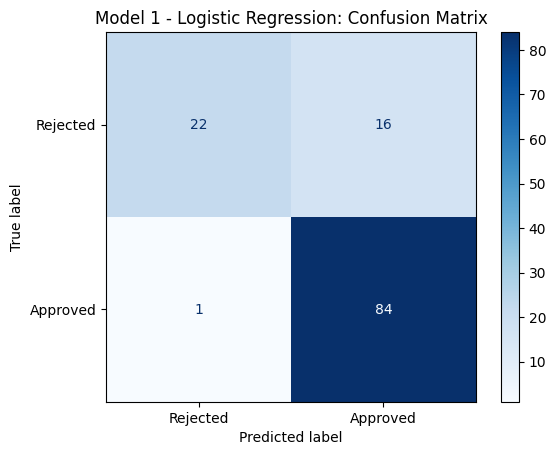

In [21]:
accuracy1 = accuracy_score(y_test, y_pred1)
print(f"Model 1 - Accuracy: {accuracy1:.4f}")

# (Precision, Recall, F1)
print("\nModel 1 - Classification Report:")
print(classification_report(y_test, y_pred1, target_names=["Rejected", "Approved"]))

# Confusion Matrix
cm1 = confusion_matrix(y_test, y_pred1)
disp1 = ConfusionMatrixDisplay(confusion_matrix=cm1, display_labels=["Rejected", "Approved"])
disp1.plot(cmap="Blues")
plt.title("Model 1 - Logistic Regression: Confusion Matrix")
plt.show()

the model is week on rejected 0.58

# The seconed model

Model 2 - Accuracy: 0.8293

Model 2 - Classification Report:
              precision    recall  f1-score   support

    Rejected       0.77      0.63      0.70        38
    Approved       0.85      0.92      0.88        85

    accuracy                           0.83       123
   macro avg       0.81      0.77      0.79       123
weighted avg       0.83      0.83      0.82       123



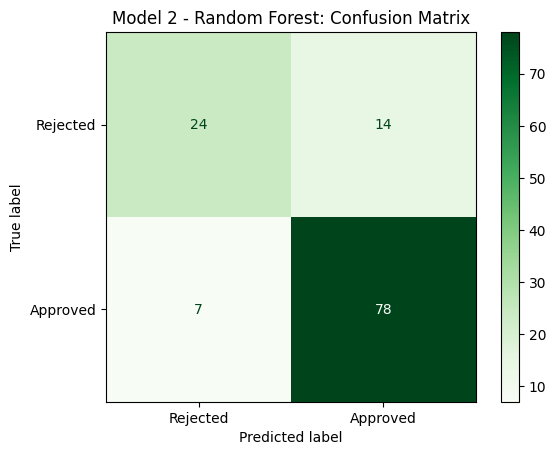

In [22]:
accuracy2 = accuracy_score(y_test, y_pred2)
print(f"Model 2 - Accuracy: {accuracy2:.4f}")

print("\nModel 2 - Classification Report:")
print(classification_report(y_test, y_pred2, target_names=["Rejected", "Approved"]))

# Confusion Matrix
cm2 = confusion_matrix(y_test, y_pred2)
disp2 = ConfusionMatrixDisplay(confusion_matrix=cm2, display_labels=["Rejected", "Approved"])
disp2.plot(cmap="Greens")
plt.title("Model 2 - Random Forest: Confusion Matrix")
plt.show()

# Comparison between the first and second model.

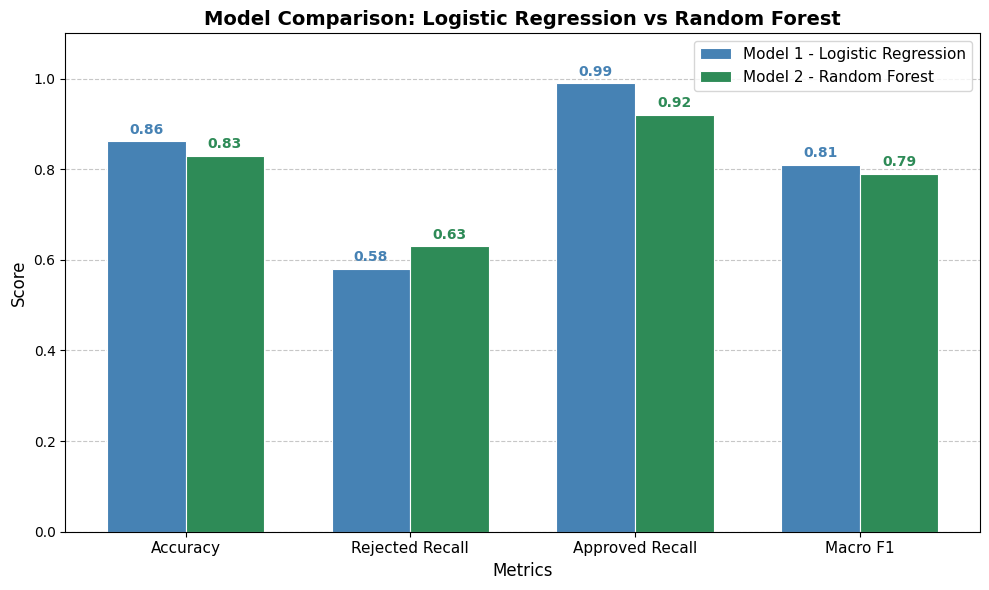

In [23]:
import matplotlib.pyplot as plt
import numpy as np



models = ['Model 1\nLogistic Regression', 'Model 2\nRandom Forest']
metrics = ['Accuracy', 'Rejected Recall', 'Approved Recall', 'Macro F1']

model1_scores = [0.8618, 0.58, 0.99, 0.81]
model2_scores = [0.8293, 0.63, 0.92, 0.79]

x = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))

bars1 = ax.bar(x - width/2, model1_scores, width, label='Model 1 - Logistic Regression',
               color='steelblue', edgecolor='white', linewidth=0.8)
bars2 = ax.bar(x + width/2, model2_scores, width, label='Model 2 - Random Forest',
               color='seagreen', edgecolor='white', linewidth=0.8)

for bar in bars1:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f'{bar.get_height():.2f}', ha='center', va='bottom', fontsize=10, color='steelblue', fontweight='bold')

for bar in bars2:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f'{bar.get_height():.2f}', ha='center', va='bottom', fontsize=10, color='seagreen', fontweight='bold')

ax.set_xlabel('Metrics', fontsize=12)
ax.set_ylabel('Score', fontsize=12)
ax.set_title('Model Comparison: Logistic Regression vs Random Forest', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(metrics, fontsize=11)
ax.set_ylim(0, 1.1)
ax.legend(fontsize=11)
ax.yaxis.grid(True, linestyle='--', alpha=0.7)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()